# UMAP Embeddings for Inference APIs

## Non-Parametric vs Parametric UMAP

### Learning Objectives

By the end of this notebook you should be able to:

- Explain what embeddings are
- Compare PCA, UMAP, and Parametric UMAP
- Generate 2D and 3D embeddings
- Understand fit() vs transform()
- Persist trained UMAP models
- Integrate embeddings into machine learning APIs
- Evaluate production deployment considerations

---

Homework Alignment:

This notebook directly supports the assignment requiring:

- UMAP embedding calculation
- Configurable UMAP parameters
- Persistence across API calls
- Returning embeddings with predictions
- Error handling
- Performance considerations

In [ ]:
# Uncomment if needed
!pip install umap-learn
!pip install plotly
!pip install ipywidgets

# Instructor Notes

Common Misconceptions:

1. UMAP should be retrained during every API request.

2. Embedding coordinates have direct semantic meaning.

3. Embeddings are stable when training repeatedly.

Key Concepts:

- fit() learns the manifold
- transform() projects onto an existing manifold
- persistence is critical for consistency
- embeddings support explainability and monitoring

# What Are Embeddings?

Suppose our model contains 13 input features:

```text
Alcohol
Malic Acid
Ash
Alcalinity
...
```

Visualizing a 13-dimensional space is impossible.

UMAP creates a lower dimensional representation:

```text
13 Features
     ↓
    UMAP
     ↓
   (x,y)
```

allowing us to:

- visualize data
- discover clusters
- monitor drift
- identify anomalies
- enhance interpretability

# PCA vs UMAP

| Method | Linear | Nonlinear | Transform New Data |
|----------|----------|----------|----------|
| PCA | Yes | No | Yes |
| t-SNE | No | Yes | No |
| UMAP | No | Yes | Yes |
| Parametric UMAP | No | Yes | Yes |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.decomposition import PCA

import umap

In [2]:
wine = load_wine()

X = wine.data
y = wine.target

print("Shape:", X.shape)

Shape: (178, 13)


# PCA Projection

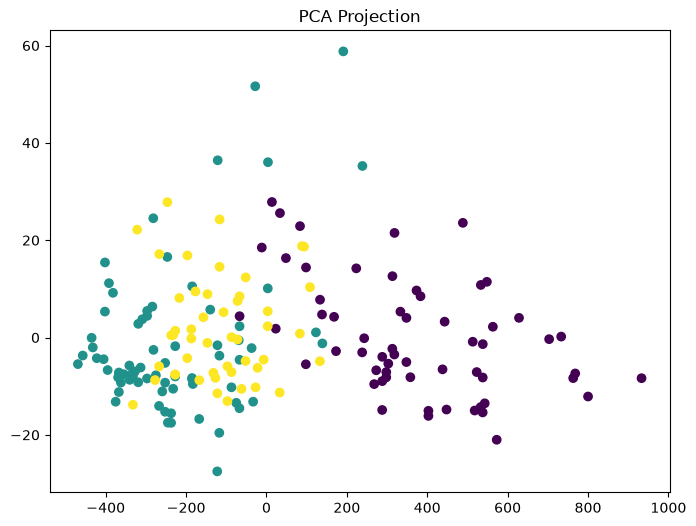

In [3]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

plt.figure(figsize=(8,6))
plt.scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=y,
    cmap="viridis"
)

plt.title("PCA Projection")
plt.show()

# Basic UMAP Projection

In [4]:
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    random_state=42
)

X_umap = reducer.fit_transform(X)

/Users/hikaruizumitani/Documents/3_大学/3_USU/Fall2026/DATA6580_MLOps/data6580/data6580_hw/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


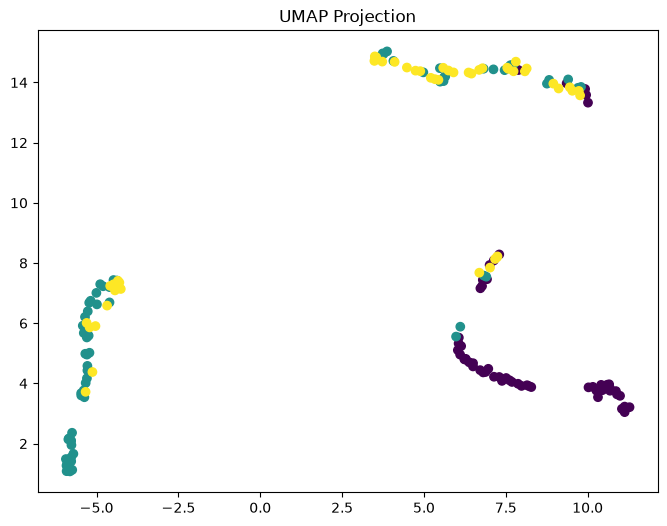

In [5]:
plt.figure(figsize=(8,6))

plt.scatter(
    X_umap[:,0],
    X_umap[:,1],
    c=y,
    cmap="viridis"
)

plt.title("UMAP Projection")
plt.show()

## Discussion Prompt

Compare PCA and UMAP:

- Which clusters appear more distinct?
- Which technique better preserves local neighborhoods?
- Why might UMAP be preferred for visualization?

# Understanding UMAP Parameters

## n_neighbors

Controls:

- Local structure
- Global structure

Smaller values:

- focus on local neighbors

Larger values:

- preserve broader structure

---

## min_dist

Controls:

- tightness of clusters

# Interactive Sweep: n_neighbors

In [6]:
from ipywidgets import interact

In [7]:
@interact(n_neighbors=(2,100,1))
def explore_neighbors(n_neighbors=15):

    reducer = umap.UMAP(
        n_neighbors=n_neighbors,
        random_state=42
    )

    emb = reducer.fit_transform(X)

    plt.figure(figsize=(8,5))

    plt.scatter(
        emb[:,0],
        emb[:,1],
        c=y,
        cmap="viridis"
    )

    plt.title(f"n_neighbors={n_neighbors}")
    plt.show()

interactive(children=(IntSlider(value=15, description='n_neighbors', min=2), Output()), _dom_classes=('widget-…

### Checkpoint

Compare:

- n_neighbors=5
- n_neighbors=50

How do the clusters change?

# Interactive Sweep: min_dist

In [ ]:
@interact(min_dist=(0.0,1.0,0.01))
def explore_distance(min_dist=0.1):

    reducer = umap.UMAP(
        min_dist=min_dist,
        random_state=42
    )

    emb = reducer.fit_transform(X)

    plt.figure(figsize=(8,5))

    plt.scatter(
        emb[:,0],
        emb[:,1],
        c=y,
        cmap="viridis"
    )

    plt.title(f"min_dist={min_dist:.2f}")
    plt.show()

interactive(children=(FloatSlider(value=0.1, description='min_dist', max=1.0, step=0.01), Output()), _dom_clas…

### Checkpoint

Compare:

- min_dist=0.01
- min_dist=0.75

What changes do you observe?

# 3D UMAP Embeddings

In [11]:
reducer_3d = umap.UMAP(
    n_components=3,
    random_state=42
)

embedding_3d = reducer_3d.fit_transform(X)

embedding_3d.shape

/Users/hikaruizumitani/Documents/3_大学/3_USU/Fall2026/DATA6580_MLOps/data6580/data6580_hw/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(178, 3)

In [12]:
import plotly.express as px

In [13]:
df_3d = pd.DataFrame(
    {
        "x": embedding_3d[:,0],
        "y": embedding_3d[:,1],
        "z": embedding_3d[:,2],
        "class": y
    }
)

fig = px.scatter_3d(
    df_3d,
    x="x",
    y="y",
    z="z",
    color="class"
)

fig.show()

## Discussion

When might a 3D embedding be preferable to a 2D embedding?

# Non-Parametric UMAP

Standard UMAP is non-parametric.

It learns:

```text
Data
  ↓
Manifold Graph
  ↓
Embedding
```

No neural network is trained.

In [14]:
reducer = umap.UMAP(random_state=42)

reducer.fit(X)

sample = X[0].reshape(1,-1)

embedded_sample = reducer.transform(sample)

embedded_sample

/Users/hikaruizumitani/Documents/3_大学/3_USU/Fall2026/DATA6580_MLOps/data6580/data6580_hw/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


array([[6.671867, 4.225487]], dtype=float32)

# fit() vs transform()

Production systems should:

```python
reducer.fit(training_data)
```

once

and

```python
reducer.transform(new_data)
```

repeatedly

# Why Persistence Matters

BAD

```text
request
   ↓
fit UMAP
   ↓
transform
```

GOOD

```text
training
   ↓
fit
   ↓
save model
   ↓
load
   ↓
transform requests
```

# Persisting UMAP Models with joblib

In [15]:
import joblib

In [16]:
joblib.dump(
    reducer,
    "umap_model.pkl"
)

['umap_model.pkl']

In [17]:
loaded_reducer = joblib.load(
    "umap_model.pkl"
)

In [18]:
loaded_reducer.transform(sample)

array([[6.671867, 4.225487]], dtype=float32)

## Checkpoint

Why is model persistence required by the assignment?

# Parametric UMAP

Parametric UMAP trains a neural network.

```text
Features
   ↓
Neural Network
   ↓
Embedding
```

Benefits:

- faster inference
- scalable deployment
- neural network representation

Drawback:

- longer training time

In [ ]:
# Optional
!pip install "umap-learn[parametric_umap]"

In [36]:
PARAMETRIC_AVAILABLE = True

try:
    from umap.parametric_umap import ParametricUMAP
except:
    PARAMETRIC_AVAILABLE = False

/Users/hikaruizumitani/Documents/3_大学/3_USU/Fall2026/DATA6580_MLOps/data6580/data6580_hw/.venv/lib/python3.14/site-packages/umap/parametric_umap.py:41: UserWarning: Torch and ONNX required for exporting to those formats.
  warn("""Torch and ONNX required for exporting to those formats.""")


In [37]:
if PARAMETRIC_AVAILABLE:

    pumap = ParametricUMAP(
        n_neighbors=15,
        min_dist=0.1,
        n_components=2
    )

    parametric_embedding = pumap.fit_transform(X, y)

    print(parametric_embedding.shape)

else:

    print("Parametric UMAP not installed")

Epoch 1/10


/Users/hikaruizumitani/Documents/3_大学/3_USU/Fall2026/DATA6580_MLOps/data6580/data6580_hw/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
/Users/hikaruizumitani/Documents/3_大学/3_USU/Fall2026/DATA6580_MLOps/data6580/data6580_hw/.venv/lib/python3.14/site-packages/keras/src/layers/layer.py:436: UserWarning: `build()` was called on layer 'umap_model', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


276/276 ━━━━━━━━━━━━━━━━━━━━ 1s 877us/step - loss: 0.2363
Epoch 2/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 656us/step - loss: 0.2336
Epoch 3/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 703us/step - loss: 0.2325
Epoch 4/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 653us/step - loss: 0.2319
Epoch 5/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 744us/step - loss: 0.2305
Epoch 6/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 649us/step - loss: 0.2307
Epoch 7/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 648us/step - loss: 0.2291
Epoch 8/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 655us/step - loss: 0.2294
Epoch 9/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 646us/step - loss: 0.2285
Epoch 10/10
276/276 ━━━━━━━━━━━━━━━━━━━━ 0s 642us/step - loss: 0.2284
(178, 2)


# Visual Comparison

PCA vs UMAP vs Parametric UMAP

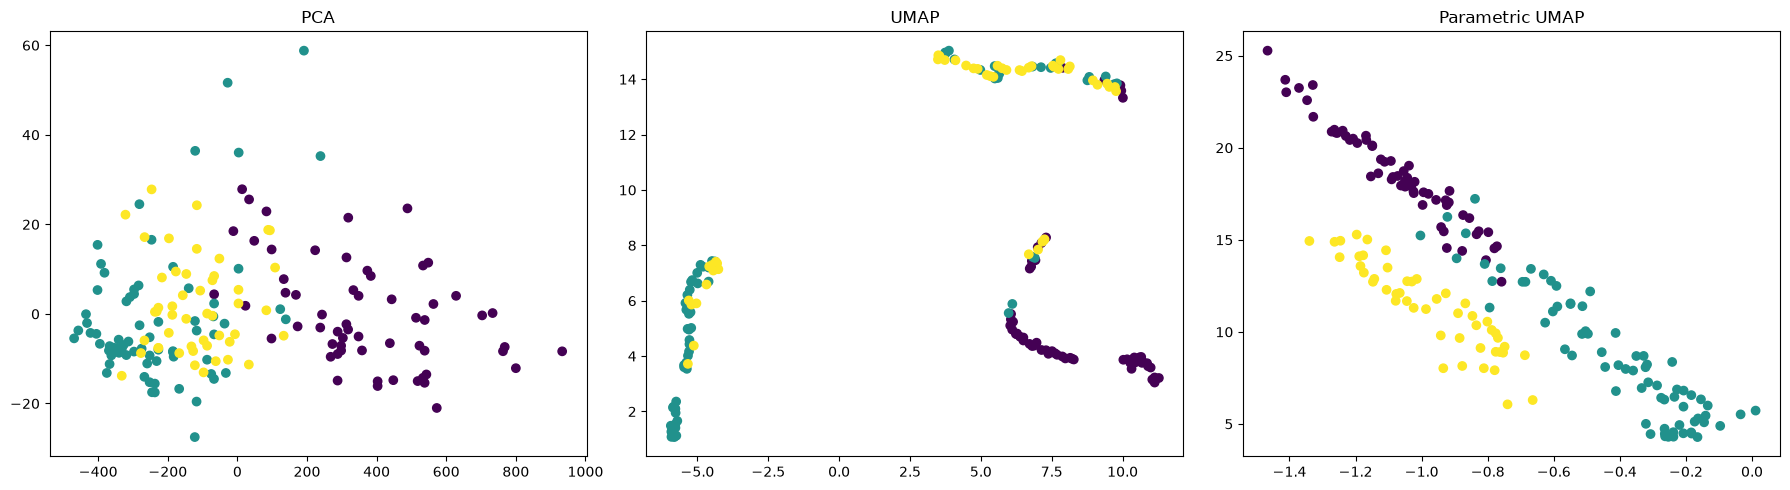

In [38]:
fig, axs = plt.subplots(
    1,
    3,
    figsize=(18,5)
)

axs[0].scatter(
    X_pca[:,0],
    X_pca[:,1],
    c=y
)
axs[0].set_title("PCA")

axs[1].scatter(
    X_umap[:,0],
    X_umap[:,1],
    c=y
)
axs[1].set_title("UMAP")

if PARAMETRIC_AVAILABLE:

    axs[2].scatter(
        parametric_embedding[:,0],
        parametric_embedding[:,1],
        c=y
    )

    axs[2].set_title(
        "Parametric UMAP"
    )

plt.tight_layout()
plt.show()

## Checkpoint

Which projection best separates the classes?

Why?

# Performance Comparison

In [39]:
import time

In [40]:
start = time.time()

_ = reducer.transform(X)

nonparam_time = time.time() - start

print(
    "Non Parametric:",
    nonparam_time
)

Non Parametric: 0.0019562244415283203


In [41]:
if PARAMETRIC_AVAILABLE:

    start = time.time()

    _ = pumap.transform(X)

    param_time = (
        time.time() - start
    )

    print(
        "Parametric:",
        param_time
    )

Parametric: 0.08671212196350098


## Discussion

Which approach would be preferred for:

- a dashboard?
- a streaming system?
- millions of transformations per day?

# API Integration Example

In [42]:
from sklearn.ensemble import RandomForestClassifier

In [43]:
classifier = RandomForestClassifier(
    random_state=42
)

classifier.fit(X, y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

## Production Architecture

```text
Request
   │
   ▼
Classifier
   │
   ├──── Label
   │
   ▼
UMAP Transform
   │
   ▼
Embedding
   │
   ▼
Response
```

In [44]:
def predict(features):

    prediction = int(
        classifier.predict(
            [features]
        )[0]
    )

    embedding = reducer.transform(
        [features]
    )[0]

    return {
        "label": prediction,
        "embeddings": {
            "kind": "inputs",
            "x": float(embedding[0]),
            "y": float(embedding[1])
        }
    }

In [45]:
predict(X[0])

{'label': 0,
 'embeddings': {'kind': 'inputs',
  'x': 6.6718668937683105,
  'y': 4.225487232208252}}

# FastAPI Example

This directly maps to the homework assignment.

In [ ]:
fastapi_example = """
from fastapi import FastAPI
from pydantic import BaseModel
import joblib

app = FastAPI()

classifier = joblib.load(
    'classifier.pkl'
)

umap_model = joblib.load(
    'umap_model.pkl'
)

class PredictionRequest(
    BaseModel
):
    features: list[float]

@app.post('/predict')
def predict(request):

    label = classifier.predict(
        [request.features]
    )[0]

    embedding = (
        umap_model.transform(
            [request.features]
        )[0]
    )

    return {
        'label': int(label),
        'embeddings': {
            'kind':'inputs',
            'x': float(embedding[0]),
            'y': float(embedding[1])
        }
    }
"""

print(fastapi_example)

# Example Assignment Response

In [46]:
example_response = {
    "label": 1,
    "embeddings": {
        "kind": "inputs",
        "x": 0.24,
        "y": -0.38
    }
}

example_response

{'label': 1, 'embeddings': {'kind': 'inputs', 'x': 0.24, 'y': -0.38}}

# Error Handling

In [47]:
def safe_predict(features):

    try:

        return predict(
            features
        )

    except Exception as ex:

        return {
            "error": str(ex)
        }

In [48]:
safe_predict([1,2,3])

{'error': 'X has 3 features, but RandomForestClassifier is expecting 13 features as input.'}

Potential Errors:

- wrong feature count
- missing values
- unloaded model
- bad input types

# Scaling Considerations

Strategies:

1. Cache models in memory

2. Batch transform records

3. Avoid retraining during inference

4. Use Parametric UMAP for very large deployments

5. Persist fitted models

## Checkpoint

When would Parametric UMAP be superior to standard UMAP?

# Final Reflection

Answer the following:

1. What problem does UMAP solve?
2. Why should UMAP be persisted?
3. What is the difference between Parametric and Non-Parametric UMAP?
4. How could embeddings be used for drift detection?
5. How would you scale this system for millions of requests?

---

End of notebook.

In [49]:
target_row = X[0:1]
target_row

array([[1.423e+01, 1.710e+00, 2.430e+00, 1.560e+01, 1.270e+02, 2.800e+00,
        3.060e+00, 2.800e-01, 2.290e+00, 5.640e+00, 1.040e+00, 3.920e+00,
        1.065e+03]])

In [50]:
target_row_embedding = pumap.transform(X[0:1])

In [52]:
target_row_embedding

array([[-1.0211734, 18.15094  ]], dtype=float32)

In [57]:
target_row2 = X[2:3]
target_row2

array([[1.316e+01, 2.360e+00, 2.670e+00, 1.860e+01, 1.010e+02, 2.800e+00,
        3.240e+00, 3.000e-01, 2.810e+00, 5.680e+00, 1.030e+00, 3.170e+00,
        1.185e+03]])

In [58]:
target_row_embedding2 = pumap.transform(X[2:3])

In [59]:
target_row_embedding2

array([[-1.1120794, 19.236807 ]], dtype=float32)